This comparisons are different than the ones we had because now we changed the IC to have the peak change in the x* we have

## Setup

### Imports

In [1]:
# ── Imports ──
import os, heapq, itertools, time, json
from datetime import date
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback, CheckpointCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
from scipy.interpolate import CubicSpline, make_interp_spline

### Problem: Burgers with IC D (peak at the middle), grid, exact solution, boundary data

In [2]:
# ── Problem: Burgers  u_t + u u_x = alpha u_xx  on [0, 1], inflow / outflow Dirichlet data from the exact solution ──
#   IC "D": the peak starts at the middle, so u changes a lot there.  u0 = C_BG + A_W cos(2 pi (x - X_PK) / L_W), u in [0.6, 1.8] > 0
PROBLEM  = "inflow_smooth"                 # name used in the run folders
alpha, T = 0.1, 0.5
a = lambda u: u                            # advection speed: Burgers
C_BG, A_W, L_W, X_PK = 1.0, 0.8, 1.5, 0.5
u0 = lambda x: C_BG + A_W * np.cos(2 * np.pi * (x - X_PK) / L_W)
F0 = lambda x: C_BG * x + A_W * L_W / (2 * np.pi) * (np.sin(2 * np.pi * (x - X_PK) / L_W) + np.sin(2 * np.pi * X_PK / L_W))   # integral of u0 from 0
A_MAX = C_BG + A_W

# ── Grid ──
# explicit advection + diffusion (LW, FD-3) is stable for 2r + nu^2 <= 1, r = alpha dt/dx^2, nu = A_MAX dt/dx; 0.9 for margin
nx = 50
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole), as a weighted average on the whole line ──
#    u(x, t) = sum (x - y)/t W / sum W,   W = exp(-F0(y)/(2 alpha) - (x - y)^2 / (4 alpha t)),   y on a uniform grid
#    reaching A_MAX * T to the left (feet of the characteristics) and 8 kernel widths on both sides.
_s = 8 * np.sqrt(2 * alpha * T)
_lo, _hi = -A_MAX * T - _s, 1 + _s
_Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
_FY = F0(_Y) / (2 * alpha)

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if t <= 0:
        return u0(x)
    out = np.empty(len(x))
    for i in range(0, len(x), 50):                             # chunks of x, to keep memory small
        xs = x[i:i + 50, None]
        E  = -_FY - (xs - _Y)**2 / (4 * alpha * t)
        W  = np.exp(E - E.max(axis=1, keepdims=True))
        out[i:i + 50] = ((xs - _Y) / t * W).sum(1) / W.sum(1)
    return out

# exact values on the grid, one time level at a time when first needed (u_true ONLY for checks, reports, and wall data)
_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data: u at x = 0 and x = 1 as functions of t (given data, like the IC); cubic spline between levels ──
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])            # (time, [left, right])
_gs = CubicSpline(_tb, _gb)
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"IC D: alpha = {alpha}, T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

IC D: alpha = 0.1, T = 0.5 | nx = 50, nt = 276, dx = 0.02041, dt = 1.818e-03 | r = 0.44, nu_max = 0.16, 2r + nu^2 = 0.90


### Taylor predictor

In [3]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

### Local error estimate (score)

In [4]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
# PDE-specific part: Taylor coefficients with every time derivative replaced using Burgers, u_t = alpha u_xx - u u_x
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2                                     # Burgers term: - u_x^2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2                               # Burgers term: - 3 u_x u_xx
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)   # Burgers term: 2 u_x (...)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

### Coarse guess of u and its derivatives

In [5]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score, influence) ──
# Lax-Wendroff on a grid K_COARSE times coarser, from the initial condition to T, with the same boundary data; computed once.
K_COARSE = 3
xc  = np.linspace(0.0, 1.0, (nx - 1) // K_COARSE + 1)
hc  = xc[1] - xc[0]
_c2, _c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                 # same stability rule as the main grid
tau = T / int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2))))
tc  = np.arange(0.0, T + tau / 2, tau)
Uc  = [u0(xc)]
for j in range(1, len(tc)):
    u, ui = Uc[-1], Uc[-1][1:-1]
    r, nu = alpha * tau / hc**2, a(ui) * tau / hc
    n = u.copy()
    n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
    n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
    Uc.append(n)
G_COARSE = len(xc) * len(tc)                                                  # cost of the guess (grid points)

# ── Smooth fit in x at each coarse time: a quintic spline through the coarse values, differentiated exactly ──
Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
for j, u in enumerate(Uc):
    sp = make_interp_spline(xc, u, k=5)
    for k in range(5):
        Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)

# ── Linear in time onto our grid: GUESS[k, it, ix] = k-th x-derivative of the guess at grid point (ix, it) ──
tg = np.arange(nt) * dt
jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
f  = ((tg - tc[jj]) / tau)[None, :, None]
GUESS = (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1]
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                 # (u, u_x, u_xx, u_xxx, u_xxxx) at q

### The map (with the SAME_LEVEL switch: 0 = original window)

In [6]:
# ── Known data: the initial condition and the walls are given, not computed ──
# their values are the exact solution there: u0 at t = 0, the boundary data g_left / g_right on the walls
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug

# ── Speed at p for its weights: from the guess, rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs (grid points), with p's guessed speed; None if not admissible.
    Cached by (shape, speed). Solved with the neighbours sorted (latest level first, then left to right), so the
    result never depends on the order the neighbours were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]                  # back to the order of nbs
    return w

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p))

# ── Same-level neighbours on BOTH sides ──
#   SAME_LEVEL = k > 0 adds the cells (-k..-1, 0) and (1..k, 0): neighbours on p's own time level, left AND right.
#   No linear solve: within a level the same-level links must form no cycle (a mask forbids any link that would close one),
#   so the level can be computed in dependency order. Because a point's same-level users can come after it, its influence
#   beta is only final when its whole level is done: beta is passed down ONE LEVEL AT A TIME, when the level is complete.
#   SAME_LEVEL = 0 gives back the original window (needed for the old agents).
SAME_LEVEL = 0

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded latest t first, left to right within a level. Stencils are chosen point by
# point; when the last point of a level is expanded, the level is "closed": its beta is passed down (users before the
# points they use), which completes the beta of the lower points before they are expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {},
            "same": {}, "level": []}               # same: p -> same-level points p uses | level: expanded points of the open level

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def reaches(m, a, b):
    """True if same-level point a uses b, directly or through other same-level points."""
    stack, seen = [a], set()
    while stack:
        q = stack.pop()
        if q == b:
            return True
        if q not in seen:
            seen.add(q); stack.extend(m["same"].get(q, []))
    return False

def forbidden(m, p):
    """Window cells p may not use: same-level points that already use p (directly or not), which would close a cycle."""
    return [k for k in range(N_CELLS) if WINDOW[k][1] == 0 and not is_known(place(p, k)) and reaches(m, place(p, k), p)]

def users_first(m, pts):
    """The points of one level ordered so that every point comes before the same-level points it uses."""
    pts, order, done = set(pts), [], set()
    def visit(q):                                  # depth-first: a point is placed after all its same-level users
        if q in done:
            return
        done.add(q)
        for r in pts:
            if q in m["same"].get(r, []):
                visit(r)
        order.append(q)
    for q in sorted(pts):
        visit(q)
    return order

def close_level(m):
    """Pass the open level's beta down (users first) and return the level's points (their beta is now final)."""
    pts = m["level"]
    for p in users_first(m, pts):
        nbs, w = m["stencil"][p]
        for q, wq in zip(nbs, w):
            if not is_known(q):
                m["beta"][q] += m["beta"][p] * wq
    m["level"] = []
    return pts

def expand(m, nbs):
    """Give the next point the stencil nbs. Returns (p, w, closed): closed = the points whose beta became final now."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    m["same"][p] = [q for q in nbs if q[1] == p[1] and not is_known(q)]
    for q in nbs:
        if not is_known(q) and q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
    m["level"].append(p)
    level_done = not m["pending"] or m["pending"][0][0] != it
    return p, w, (close_level(m) if level_done else [])

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p (it must respect forbidden(m, p))."""
    m = start_map(z_star)
    while m["pending"]:
        expand(m, choose(m, next_point(m)))
    return m

# ── Forward pass: values bottom-up; within a level, every point after the same-level points it uses ──
# The map fixes the neighbours (chosen with the guessed speed). Each point then re-solves its weights with the speed
# of its own computed value (picard steps; 0 = keep the map's weights), so the guessed speed never enters the values.
# The weights actually used are kept in m["w_used"] (report needs them).
def forward_order(m):
    order = []
    for t in sorted({p[1] for p in m["stencil"]}):
        order += users_first(m, [p for p in m["stencil"] if p[1] == t])[::-1]
    return order

def evaluate(m, picard=1):
    u_hat, m["w_used"] = {}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in forward_order(m):
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, a(w @ v))             # speed from the value just computed
            if w_new is None:                                   # not admissible: keep the last weights
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat
lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]

### Window, admissible stencils, mask, rules, report

In [7]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = ([(k, 0) for k in list(range(-SAME_LEVEL, 0)) + list(range(1, SAME_LEVEL + 1))]
           + [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)])
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p ──
# Cached by p's local situation and guessed speed: the stencils, which cells they use, and their moments
# sum_q w_q dx^i dt^j for each Taylor term. The score at p is then |moments @ Taylor coefficients at p|.
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def allowed_sets(m, p):
    """Admissible stencils at p that use no forbidden (cycle-closing) cell: (sets, uses, scores) restricted to them.
    Cached on the map for the current point (it only changes when a stencil is placed), so the 5 picks of a point share it."""
    key = (p, len(m["stencil"]))
    if m.get("_allowed_key") != key:
        sets, uses, sc = admissible(p)
        bad = forbidden(m, p)
        ok = ~uses[:, bad].any(axis=1) if bad else np.ones(len(sets), dtype=bool)
        m["_allowed"] = ([s for s, o in zip(sets, ok) if o], uses[ok], sc[ok]) if bad else (sets, uses, sc)
        m["_allowed_key"] = key
    return m["_allowed"]

def pick_mask(m, p, picks):
    """Cell k may be picked next if some allowed stencil contains the picks so far plus k."""
    _, uses, _ = allowed_sets(m, p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

def lowest_score(m, p):
    sets, _, sc = allowed_sets(m, p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]
def report(m):
    """Points, true error at z*, exact bound sum |beta delta| with the weights the forward pass used (u_true ONLY here)."""
    z = m["z_star"]
    u_hat, W = evaluate(m), m["w_used"]
    beta = {z: 1.0}
    for p in forward_order(m)[::-1]:                              # every user before the points it uses
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}

### Reward units and the environment

In [8]:
# ── Units of the reward ──
#   accuracy: the estimated error share |beta_p| s_p, in units of EPS (a fixed target error for the problem, same for every query)
#   cost:     new points, in units of N_LW (the point count of the Lax-Wendroff map of the same z*: "a classical solve")
EPS = 1e-3

_nlw_cache = {}
def n_lw(z):
    """Points of the LW map of z* (the cost unit)."""
    if z not in _nlw_cache:
        _nlw_cache[z] = len(build_map(z, lw)["stencil"])
    return _nlw_cache[z]

# ── Environment: one step = one pick; a reward each time a stencil is complete ──
#   reward of a stencil at p:  -|beta_p| s_p / EPS  -  lam * (new points) / N_LW
#   lam (the price of a point) is drawn per episode, log-uniform in lam_range, and shown to the agent
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
N_OBS   = 3 * N_CELLS + 12

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(0.1, 10.0), cap=3.0):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS,), dtype=np.float32)
        self.action_space = spaces.Discrete(N_CELLS)               # one action = one window cell

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B = start_map(self.z), [], 0.0
        self._play_forced()
        return self._obs(), {}

    def _complete(self, cells):
        """Expand the next point with these cells. Reward: the points' cost now; the accuracy terms of a level when it closes."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, _, closed = expand(self.m, nbs)
        return -self._accuracy(closed) - self.lam * n_new / self.N_ref

    def _accuracy(self, pts):
        """Sum of |beta_p| s_p / EPS over points whose beta is final."""
        term = sum(abs(self.m["beta"][q]) * point_score(q, *self.m["stencil"][q]) for q in pts)
        self.B += term
        return term / EPS

    def _play_forced(self):
        """Points with only one allowed stencil need no decision."""
        r = 0.0
        while self.m["pending"]:
            sets, _, _ = allowed_sets(self.m, next_point(self.m))
            if len(sets) != 1:
                break
            r += self._complete(sets[0])
        return r


    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = [(ix, -it) for it, ix in self.m["pending"]]
        d      = guess_derivs(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points still waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam)]                                # price of a point
        return np.concatenate([picked, exists, known, glob]).astype(np.float32)

    def step(self, k):
        self.picks.append(int(k))
        p = next_point(self.m)
        if len(self.picks) < len(allowed_sets(self.m, p)[0][0]):   # still choosing p's stencil (fewer cells near the walls)
            return self._obs(), 0.0, False, False, {}
        r = self._complete(self.picks)
        self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: close the open level, then each point left unexpanded costs its worst stencil
        r -= self._accuracy(close_level(self.m)) if self.m["level"] else 0.0
        for it, ix in self.m["pending"]:
            q = (ix, -it)
            r -= abs(self.m["beta"][q]) * admissible(q)[2].max() / EPS
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "lam": self.lam,
                "score_ratio": self.B / EPS, "points_ratio": len(self.m["stencil"]) / self.N_ref}
        return np.zeros(N_OBS, np.float32), r, True, False, info

    def action_masks(self):
        return pick_mask(self.m, next_point(self.m), self.picks)

### Rules and measures

In [9]:
# ── Rules and measures: the score sum, greedy, the lean of a map, same-level use ──
def score_sum(m):
    """B = sum |beta_p| s_p: the map's estimated error bound."""
    return sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])

def greedy_rule(lam):
    """At every point the allowed stencil with the best one-step reward (beta_p as known when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = allowed_sets(m, p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

def same_level_use(m):
    """How often stencils use same-level neighbours on the left (upwind for u > 0) and on the right (downwind)."""
    left = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[1] == p[1] and q[0] < p[0] and not is_known(q))
    right = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[1] == p[1] and q[0] > p[0] and not is_known(q))
    return left, right

### Map figure and training helpers

In [10]:
# ── One figure for any finished map (used for the baselines and the training videos) ──
#   left : the map, coloured by influence |beta| on z*
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("Map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4,
            label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"Solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

# ── Helpers for training: environment factory and one deterministic run of a trained policy ──
def make_env(queries, lam_range, seed, env_cls=MapEnv):
    def _init():
        env = Monitor(ActionMasker(env_cls(queries=queries, lam_range=lam_range), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, lam, env_cls=MapEnv):
    """One episode on z* at a fixed lam, with the policy's most likely picks. Returns the finished env (map in env.m)."""
    env = env_cls(queries=[z], lam_range=(lam, lam))
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        a, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(a)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: log map numbers of every finished training episode (mean of the last 100) ──
class MapLogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.hist = {"points_ratio": [], "score_ratio": [], "finished": []}

    def _on_step(self):
        for info in self.locals["infos"]:
            if "points_ratio" in info:                              # only at the end of an episode
                for k in self.hist:
                    self.hist[k].append(float(info[k]))
        for k, v in self.hist.items():
            if v:
                self.logger.record(f"map/{k}", np.mean(v[-100:]))
        return True

# ── Callback 2: every `every` steps, run the current policy on z_plot at a fixed lam, save the figure and the numbers ──
class SnapshotCallback(BaseCallback):
    def __init__(self, z_plot, lam, every, img_dir, env_cls=MapEnv):
        super().__init__()
        self.z_plot, self.lam, self.every, self.img_dir, self.env_cls = z_plot, lam, every, img_dir, env_cls
        self.last, self.hist, self.episodes = -every, [], 0

    def _on_step(self):
        self.episodes += sum("episode" in info for info in self.locals["infos"])   # maps finished in training
        if self.num_timesteps - self.last >= self.every:
            self.last = self.num_timesteps
            env = run_policy(self.model, self.z_plot, self.lam, self.env_cls)
            if env.info["finished"]:
                rep = report(env.m)
                plot_map(env.m, f"step {self.num_timesteps:,}  ({self.episodes} maps)  |  lam {self.lam:g}  |  return {env.ret:.2f}",
                         os.path.join(self.img_dir, f"map_{self.num_timesteps:09d}.png"))
            else:
                rep = {"points": env.info["points"], "error": np.nan, "bound": np.nan}
            self.hist.append({"step": self.num_timesteps, "episodes": self.episodes, "return": env.ret, **rep})
            print(f"step {self.num_timesteps:>10,} | {self.episodes:5d} maps: return {env.ret:7.2f} | "
                  f"{rep['points']} points | bound {rep['bound']:.1e} | finished {env.info['finished']}")
        return True

### Check: map identity and rewards

In [11]:
# ── Check: the setup is consistent (map identity, rewards add up to the return) ──
z = (25, 75)
for name, rule in [("LW", lw), ("lowest score", lowest_score)]:
    m = build_map(z, rule)
    err = Ug(z) - evaluate(m, picard=0)[z]                         # the map's own weights: the identity must hold exactly
    delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
    rep = report(m)
    print(f"{name:>13s}: {rep['points']} points | true error {rep['error']:.1e} | bound {rep['bound']:.1e} | "
          f"identity {err:.6e} = {sum(m['beta'][p] * delta[p] for p in delta):.6e} | same-level left / right {same_level_use(m)}")
env = MapEnv(queries=[z], lam_range=(1.0, 1.0)); obs, _ = env.reset(seed=0)
rng, total, done = np.random.default_rng(0), 0.0, False
while not done:
    obs, r, done, _, info = env.step(rng.choice(np.flatnonzero(env.action_masks()))); total += r
print(f"SAME_LEVEL = {SAME_LEVEL}: {N_CELLS} cells, state size {N_OBS} | random episode: rewards {total:.3f} = "
      f"{-info['score_ratio'] - (info['points'] - 1) / env.N_ref:.3f} (return formula)")

           LW: 3024 points | true error 7.9e-04 | bound 8.1e-04 | identity -1.284962e-03 = -1.284962e-03 | same-level left / right (0, 0)
 lowest score: 3178 points | true error 5.3e-05 | bound 1.2e-03 | identity -2.265744e-03 = -2.265744e-03 | same-level left / right (0, 0)
SAME_LEVEL = 0: 21 cells, state size 75 | random episode: rewards -8.357 = -8.357 (return formula)


## Comparisons: the agent trained on IC D (old window, single query (25, 75), 5M steps)
Run folder `runs10-21/inflow_smooth_peak0.5_same0_z25-75_lam1-1_seed1`. All numbers use the live-speed forward pass; the exact solution is used only for reporting.

In [12]:
# ── The run: settings, model, training snapshots ──
RUN = os.path.join("runs10-21", "inflow_smooth_peak0.5_same0_z25-75_lam1-1_seed1")
cfg = json.load(open(os.path.join(RUN, "config.json")))
assert cfg["same_level"] == SAME_LEVEL and cfg["N_OBS"] == N_OBS and cfg["ic"]["X_PK"] == X_PK, "notebook settings differ from the run's"
model = MaskablePPO.load(os.path.join(RUN, "checkpoints", "ppo_final"), device="cpu")
hist  = json.load(open(os.path.join(RUN, "snapshots.json")))
Z_TRAIN, LAM = tuple(cfg["queries"][0]), cfg["lam_range"][0]
print(f"run: {RUN} | trained at z* = {Z_TRAIN} (t* = {Z_TRAIN[1] * dt:.3f}) | lam = {LAM} | {cfg['total']:,} steps | seed {cfg['seed']}")

run: runs10-21\inflow_smooth_peak0.5_same0_z25-75_lam1-1_seed1 | trained at z* = (25, 75) (t* = 0.136) | lam = 1.0 | 5,000,000 steps | seed 1


### 1. At the training query: the agent against LW, lowest score and greedy
Return = the training reward (estimated error in units of EPS, plus λ × points / LW's points). Bound = exact $\sum_p|\beta_p\delta_p|$; true error = $|\hat u(z^*)-u(z^*)|$.

        agent: return  -2.45 |  3258 points | estimate B 1.4e-03 | bound 2.8e-04 | true error 1.4e-04
           LW: return  -2.45 |  3024 points | estimate B 1.4e-03 | bound 8.1e-04 | true error 7.9e-04
 lowest score: return  -1.05 |  3178 points | estimate B 2.2e-06 | bound 1.2e-03 | true error 5.3e-05
       greedy: return  -0.53 |  1349 points | estimate B 8.3e-05 | bound 1.1e-03 | true error 4.9e-05


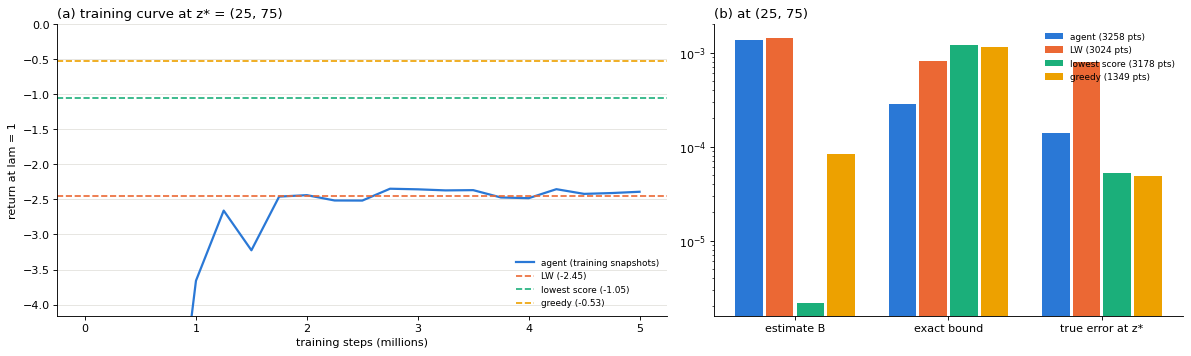

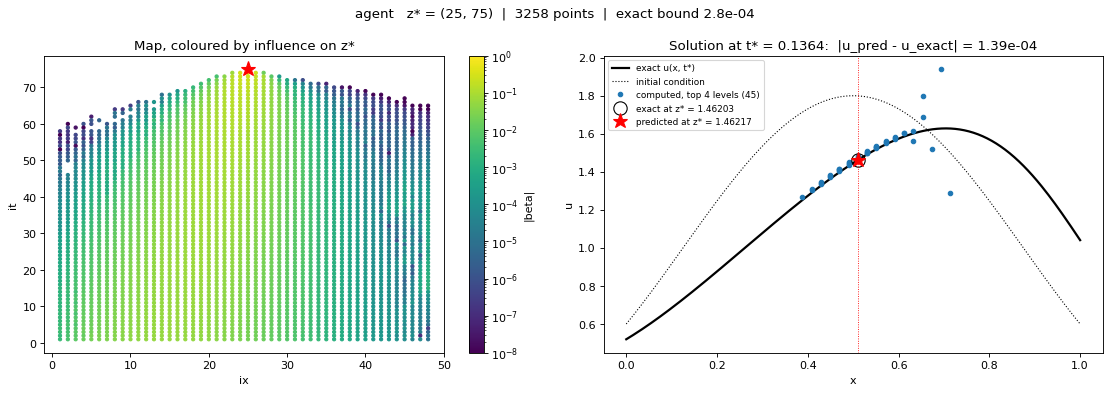

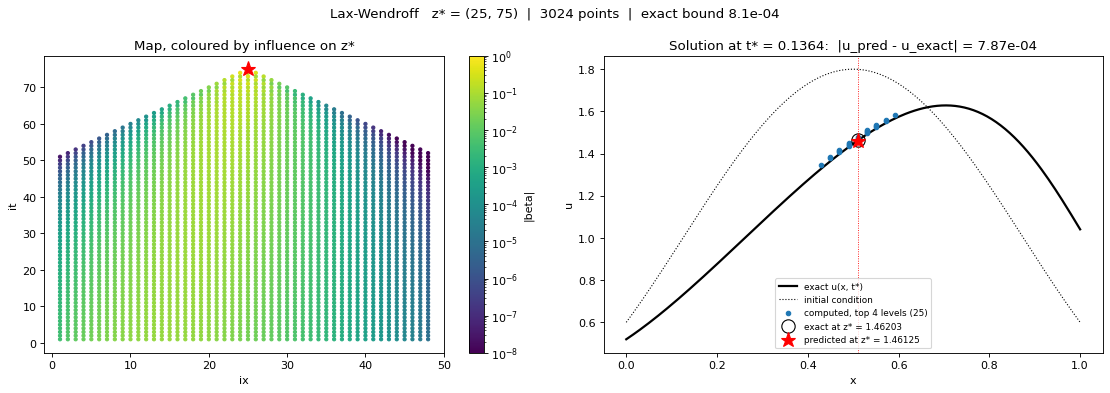

In [13]:
maps_t = {"agent": run_policy(model, Z_TRAIN, LAM).m, "LW": build_map(Z_TRAIN, lw),
          "lowest score": build_map(Z_TRAIN, lowest_score), "greedy": build_map(Z_TRAIN, greedy_rule(LAM))}
res_t = {}
for name, mm in maps_t.items():
    rep = report(mm)
    res_t[name] = dict(ret=-score_sum(mm) / EPS - LAM * (rep["points"] - 1) / n_lw(Z_TRAIN), est=score_sum(mm), **rep)
    print(f"{name:>13s}: return {res_t[name]['ret']:6.2f} | {rep['points']:5d} points | estimate B {res_t[name]['est']:.1e} | "
          f"bound {rep['bound']:.1e} | true error {rep['error']:.1e}")

COL4 = {"agent": "#2a78d6", "LW": "#eb6834", "lowest score": "#1baf7a", "greedy": "#eda100"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
a1.plot([h["step"] / 1e6 for h in hist], [h["return"] for h in hist], "-", color=COL4["agent"], lw=2, label="agent (training snapshots)")
for name in ["LW", "lowest score", "greedy"]:
    a1.axhline(res_t[name]["ret"], color=COL4[name], lw=1.5, ls="--", label=f"{name} ({res_t[name]['ret']:.2f})")
a1.set_ylim(min(h["return"] for h in hist if h["step"] > 1e6) - 0.5, 0)
a1.set_xlabel("training steps (millions)"); a1.set_ylabel(f"return at lam = {LAM:g}")
a1.set_title(f"(a) training curve at z* = {Z_TRAIN}", loc="left"); a1.legend(fontsize=8, frameon=False, loc="lower right")
a1.grid(axis="y", color="#e5e4df", lw=0.8); a1.spines[["top", "right"]].set_visible(False)
keys = [("est", "estimate B"), ("bound", "exact bound"), ("error", "true error at z*")]
for j, name in enumerate(maps_t):
    a2.bar(np.arange(3) + (j - 1.5) * 0.2, [res_t[name][k] for k, _ in keys], width=0.18, color=COL4[name],
           label=f"{name} ({res_t[name]['points']} pts)")
a2.set_yscale("log"); a2.set_xticks(np.arange(3)); a2.set_xticklabels([l for _, l in keys])
a2.set_title(f"(b) at {Z_TRAIN}", loc="left"); a2.legend(fontsize=8, frameon=False)
a2.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
plot_map(maps_t["agent"], "agent")
plot_map(maps_t["LW"], "Lax-Wendroff")

### 2. Generalisation: 12 queries, against LW, the agent's top stencil, the best fixed stencil and lowest score
- **agent's top**: the stencil the agent uses most, used everywhere. **best fixed**: one stencil everywhere, picked at the training query by its exact bound among the agent's 30 most used stencils and the 300 lowest-score ones (the strongest fixed competitor; the exact bound is used only to pick this baseline).
- Each query also shows how much $u$ changed at $x^*$ since $t=0$ and the slope there, to check the gain is not tied to "easy" points.

In [14]:
def as_cells(p, nbs):
    return tuple(sorted(WINDOW.index((q[0] - p[0], q[1] - p[1])) for q in nbs))
_as_set = {}
def fixed_rule(s_):
    """The window cells s_ at every point where admissible, elsewhere the point's lowest-score stencil."""
    def choose(m, p):
        sets = admissible(p)[0]
        if id(sets) not in _as_set:
            _as_set[id(sets)] = set(sets)
        return [place(p, k) for k in s_] if s_ in _as_set[id(sets)] else lowest_score(m, p)
    return choose
interior = lambda p: R_X <= p[0] <= nx - 1 - R_X and p[1] > K_T
used = Counter(as_cells(p, nbs) for p, (nbs, w) in maps_t["agent"]["stencil"].items() if interior(p))
top = used.most_common(1)[0][0]
sets, _, sc = admissible(Z_TRAIN)
pool = [s_ for s_ in {s_ for s_, _ in used.most_common(30)} | {sets[i] for i in np.argsort(sc)[:300]} if s_ in set(sets)]
best = min(pool, key=lambda s_: report(build_map(Z_TRAIN, fixed_rule(s_)))["bound"])
print(f"the agent used {len(used)} stencils at interior points; most used: {[n for _, n in used.most_common(5)]}; top: {[WINDOW[k] for k in top]}")
print(f"best fixed stencil: {[WINDOW[k] for k in best]} (from {len(pool)} candidates)\n")

QUERIES_TEST = [(ix, it) for it in (50, 75, 100, 150) for ix in (12, 25, 38)]
methods = {"LW": lw, "agent": None, "agent's top": fixed_rule(top), "best fixed": fixed_rule(best), "lowest score": lowest_score}
res = {}
print(f"{'z*':>10s} {'change':>7s} {'|u_x|':>6s} | " + " | ".join(f"{n:>13s}" for n in methods) + "   (true error, points)")
for z in QUERIES_TEST:
    res[z] = {n: report(run_policy(model, z, LAM).m if r is None else build_map(z, r)) for n, r in methods.items()}
    res[z]["change"] = Ug(z) - u0(z[0] * dx)
    res[z]["slope"] = abs(Ug((z[0] + 1, z[1])) - Ug((z[0] - 1, z[1]))) / (2 * dx)
    print(f"{str(z):>10s} {res[z]['change']:7.2f} {res[z]['slope']:6.2f} | "
          + " | ".join(f"{res[z][n]['error']:.1e} {res[z][n]['points']:5d}" for n in methods) + ("  (train)" if z == Z_TRAIN else ""))
unseen = [z for z in QUERIES_TEST if z != Z_TRAIN]
print(f"\n{len(unseen)} unseen queries, relative to LW (median; wins = lower than LW):")
for n in list(methods)[1:]:
    rel = {k: [res[z][n][k] / res[z]["LW"][k] for z in unseen] for k in ("points", "bound", "error")}
    print(f"  {n:>13s}: points x{np.median(rel['points']):.2f} | bound x{np.median(rel['bound']):.2f} "
          f"(wins {sum(v < 1 for v in rel['bound'])}/{len(unseen)}) | true error x{np.median(rel['error']):.2f} "
          f"(wins {sum(v < 1 for v in rel['error'])}/{len(unseen)})")

the agent used 67 stencils at interior points; most used: [1679, 614, 156, 101, 62]; top: [(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1)]
best fixed stencil: [(-2, -1), (-1, -1), (0, -1), (1, -1), (2, -1)] (from 327 candidates)

        z*  change  |u_x| |            LW |         agent |   agent's top |    best fixed |  lowest score   (true error, points)
  (12, 50)   -0.32   2.31 | 3.7e-04  1668 | 3.4e-05  2066 | 1.0e-04  2022 | 1.0e-04  2022 | 2.8e-05  1864
  (25, 50)   -0.21   1.30 | 6.4e-04  1824 | 6.8e-05  2049 | 3.9e-05  2100 | 3.9e-05  2100 | 6.8e-05  1984
  (38, 50)    0.24   1.83 | 4.4e-04  1642 | 3.1e-04  1852 | 9.3e-05  2009 | 9.3e-05  2009 | 4.6e-05  1877
  (12, 75)   -0.42   2.02 | 3.6e-04  2868 | 6.1e-05  3266 | 1.3e-04  3222 | 1.3e-04  3222 | 5.1e-05  3173
  (25, 75)   -0.34   1.49 | 7.9e-04  3024 | 1.4e-04  3258 | 8.2e-05  3300 | 8.2e-05  3300 | 5.3e-05  3178  (train)
  (38, 75)    0.27   0.92 | 1.2e-04  2842 | 4.9e-04  3042 | 2.3e-04  3209 | 2.3e-04  3209 | 2.0e-05  30

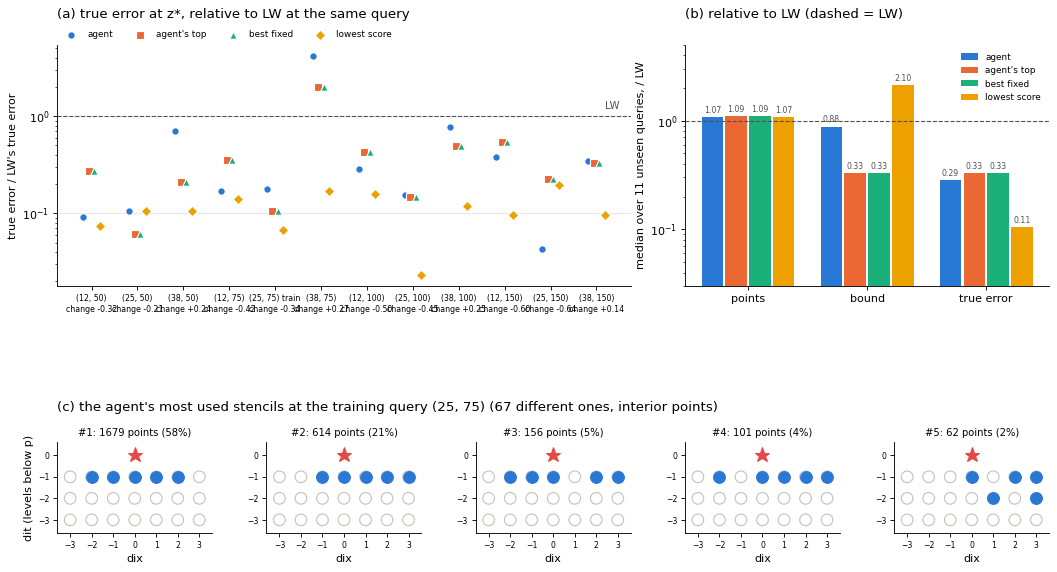

In [15]:
# ── Figure: (a) true error / LW per query, (b) medians over the unseen queries, (c) the agent's most used stencils ──
METHODS = ["agent", "agent's top", "best fixed", "lowest score"]
COLORS  = {"agent": "#2a78d6", "agent's top": "#eb6834", "best fixed": "#1baf7a", "lowest score": "#eda100"}
MARKERS = {"agent": "o", "agent's top": "s", "best fixed": "^", "lowest score": "D"}
ratio = lambda z, n, k: res[z][n][k] / res[z]["LW"][k]
fig = plt.figure(figsize=(16, 8.5))
gs = fig.add_gridspec(2, 5, height_ratios=[1.5, 1], hspace=0.6, wspace=0.35)
ax = fig.add_subplot(gs[0, :3])
xs = np.arange(len(QUERIES_TEST))
for j, n in enumerate(METHODS):
    ax.scatter(xs + (j - 1.5) * 0.12, [ratio(z, n, "error") for z in QUERIES_TEST], s=45, marker=MARKERS[n],
               color=COLORS[n], edgecolor="white", linewidth=1, label=n, zorder=3)
ax.axhline(1, color="#52514e", lw=1, ls="--", zorder=1)
ax.text(len(QUERIES_TEST) - 0.5, 1.15, "LW", color="#52514e", ha="right", va="bottom", fontsize=9)
ax.set_yscale("log"); ax.set_xticks(xs)
ax.set_xticklabels([f"{z}{' train' if z == Z_TRAIN else ''}\nchange {res[z]['change']:+.2f}" for z in QUERIES_TEST], fontsize=7)
ax.set_ylabel("true error / LW's true error")
ax.set_title("(a) true error at z*, relative to LW at the same query", loc="left", pad=24)
ax.grid(axis="y", which="major", color="#e5e4df", lw=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False, ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
ax = fig.add_subplot(gs[0, 3:])
keys = [("points", "points"), ("bound", "bound"), ("error", "true error")]
for j, n in enumerate(METHODS):
    med = [np.median([ratio(z, n, k) for z in unseen]) for k, _ in keys]
    bars = ax.bar(np.arange(3) + (j - 1.5) * 0.2, med, width=0.18, color=COLORS[n], label=n)
    for b, v in zip(bars, med):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.05, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color="#52514e")
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.set_xticks(np.arange(3)); ax.set_xticklabels([l for _, l in keys])
ax.set_ylabel(f"median over {len(unseen)} unseen queries, / LW"); ax.set_yscale("log"); ax.set_ylim(0.03, 5)
ax.set_title("(b) relative to LW (dashed = LW)", loc="left", pad=24)
ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=8, frameon=False, loc="upper right")
total = sum(used.values())
for i, (s_, cnt) in enumerate(used.most_common(5)):
    ax = fig.add_subplot(gs[1, i])
    ax.scatter(*np.array(WINDOW).T, s=110, facecolors="none", edgecolors="#c3c2b7")
    ax.scatter(*np.array([WINDOW[k] for k in s_]).T, s=110, color=COLORS["agent"])
    ax.plot(0, 0, "*", color="#e34948", ms=14)
    ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 0.6); ax.set_aspect("equal")
    ax.set_xticks(range(-3, 4)); ax.set_yticks([0, -1, -2, -3]); ax.tick_params(labelsize=7)
    ax.set_title(f"#{i + 1}: {cnt} points ({cnt / total:.0%})", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    if i == 0:
        ax.set_ylabel("dit (levels below p)")
        ax.text(0, 1.35, f"(c) the agent's most used stencils at the training query {Z_TRAIN} ({len(used)} different ones, interior points)",
                transform=ax.transAxes, fontsize=12)
    ax.set_xlabel("dix")
plt.show()

### 3. Which stencil is used where
Every point of the agent's map at the training query, coloured by its stencil (the 6 most used; grey = other, light grey = next to the walls / IC, where cells are moved onto the known data).

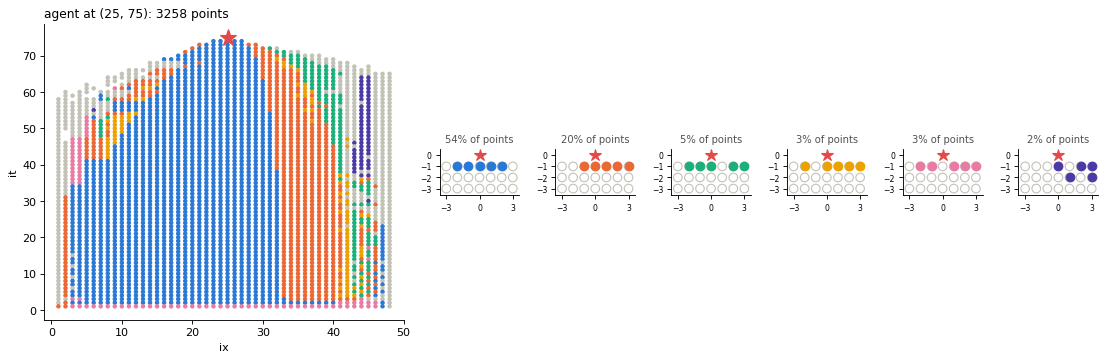

In [16]:
TOP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
def stencil_cells(p, nbs):
    offs = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    return tuple(sorted(WINDOW.index(o) for o in offs)) if all(o in WINDOW for o in offs) else None
m_ag = maps_t["agent"]
cells = {p: stencil_cells(p, nbs) for p, (nbs, w) in m_ag["stencil"].items()}
count = Counter(c for c in cells.values() if c is not None)
top6 = [c for c, _ in count.most_common(6)]
color = {c: TOP_COLORS[i] for i, c in enumerate(top6)}
fig = plt.figure(figsize=(17, 4.8))
gs = fig.add_gridspec(1, 7, width_ratios=[4.5, 1, 1, 1, 1, 1, 1], wspace=0.3)
ax = fig.add_subplot(gs[0, 0])
P = np.array(list(cells))
ax.scatter(P[:, 0], P[:, 1], s=9, c=["#e5e4df" if c is None else color.get(c, "#c3c2b7") for c in cells.values()])
ax.plot(*Z_TRAIN, "*", color="#e34948", ms=16)
ax.set_xlim(-1, nx); ax.set_xlabel("ix"); ax.set_ylabel("it"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"agent at {Z_TRAIN}: {len(m_ag['stencil'])} points", loc="left", fontsize=11)
total = sum(count.values())
for i, c in enumerate(top6):
    g = fig.add_subplot(gs[0, i + 1])
    g.scatter(*np.array(WINDOW).T, s=60, facecolors="none", edgecolors="#c3c2b7")
    g.scatter(*np.array([WINDOW[k] for k in c]).T, s=60, color=TOP_COLORS[i])
    g.plot(0, 0, "*", color="#e34948", ms=11)
    g.set_xlim(-3.6, 3.6); g.set_ylim(-3.6, 0.6); g.set_aspect("equal")
    g.set_xticks([-3, 0, 3]); g.set_yticks([0, -1, -2, -3]); g.tick_params(labelsize=7)
    g.set_title(f"{count[c] / total:.0%} of points", fontsize=9, color="#52514e"); g.spines[["top", "right"]].set_visible(False)
plt.show()

### 4. Classical solvers: true error at $z^*$ against evaluated points
Classical schemes on their own grids, refined 1–4× ($r=\alpha\Delta t/\Delta x^2$ kept fixed), with the same boundary data. WENO5's ghost nodes past the walls come from the exact solution (more data than the others get: this favours WENO). Evaluated points = grid values in $z^*$'s dependency cone (RK: × stages; CN: the whole row). Map methods run on the base grid and also pay for the guess levels up to $t^*$.

z* = (25, 75): 42 s (guess cost 150 points, added to every map method)
z* = (12, 100): 54 s (guess cost 210 points, added to every map method)
z* = (38, 150): 78 s (guess cost 300 points, added to every map method)

z* = (25, 75), t* = 0.136
                    FD-3:    3024 points | true error 2.7e-04
                      LW:    3024 points | true error 2.0e-03
                      CN:     912 points | true error 6.9e-03
              FD-5 + RK4:   14028 points | true error 3.2e-07
             WENO5 + RK3:   23355 points | true error 2.1e-07
                  LW map:    3174 points | true error 7.9e-04 | bound 8.1e-04
            lowest score:    3328 points | true error 5.3e-05 | bound 1.2e-03
                  greedy:    1499 points | true error 4.9e-05 | bound 1.1e-03
                   agent:    3408 points | true error 1.4e-04 | bound 2.8e-04

z* = (12, 100), t* = 0.182
                    FD-3:    4068 points | true error 1.3e-03
                      LW:    4068 points | tru

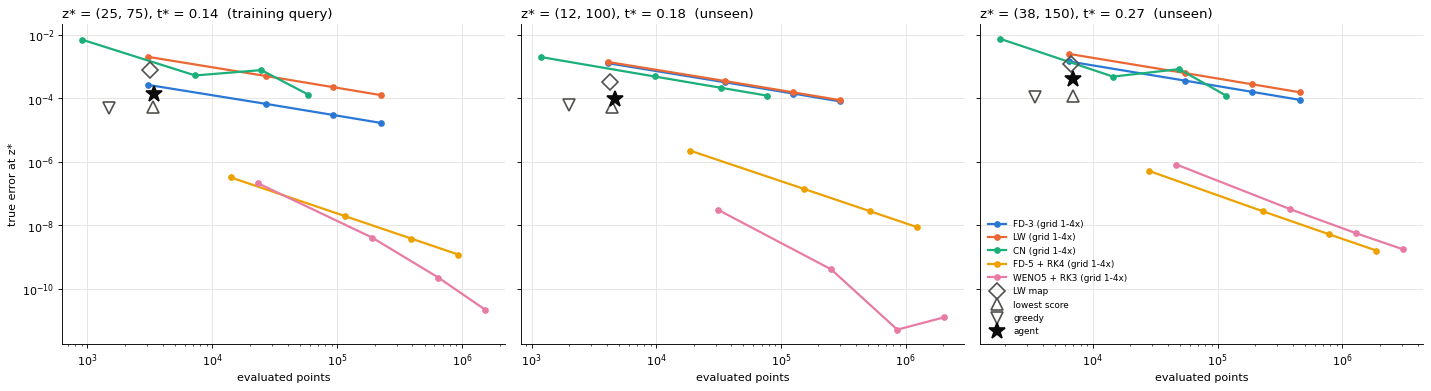

In [17]:
# ══ Comparison with classical solvers: true error at z* vs evaluated points ══
#   Classical schemes run on their own grids, refined k = 1..4 (r = alpha dt/dx^2 kept fixed), with the same boundary data
#   (inflow / outflow Dirichlet values g_left, g_right in time). Burgers: each grid point uses its own value as the speed.
#     FD-3: forward Euler + central 2nd order | LW: Lax-Wendroff | CN: Crank-Nicolson (speed from the previous step)
#     FD-5 + RK4: 4th-order central in space, RK4 in time | WENO5 + RK3: WENO5-JS (Lax-Friedrichs splitting) + SSP-RK3,
#     its ghost nodes past the walls taken from u_true (more data than the others get: this favours WENO).
#   Evaluated points = grid values computed in z*'s dependency cone (RK: x stages; CN: the whole row, it is implicit).
#   Map methods run on the base grid; they also pay for the guess levels up to t*. u_true ONLY for reporting (and WENO ghosts).
from scipy.linalg import solve_banded
_gd = _gs.derivative()                                            # time derivative of the boundary data (RK stages)

def _weno5(vm2, vm1, v0, vp1, vp2):
    """WENO5-JS value at the interface on the vp1 side of v0."""
    q0, q1, q2 = (2 * vm2 - 7 * vm1 + 11 * v0) / 6, (-vm1 + 5 * v0 + 2 * vp1) / 6, (2 * v0 + 5 * vp1 - vp2) / 6
    b0 = 13 / 12 * (vm2 - 2 * vm1 + v0)**2 + 0.25 * (vm2 - 4 * vm1 + 3 * v0)**2
    b1 = 13 / 12 * (vm1 - 2 * v0 + vp1)**2 + 0.25 * (vm1 - vp1)**2
    b2 = 13 / 12 * (v0 - 2 * vp1 + vp2)**2 + 0.25 * (3 * v0 - 4 * vp1 + vp2)**2
    w0, w1, w2 = 0.1 / (1e-6 + b0)**2, 0.6 / (1e-6 + b1)**2, 0.3 / (1e-6 + b2)**2
    return (w0 * q0 + w1 * q1 + w2 * q2) / (w0 + w1 + w2)

def rhs(u, h, t, scheme):
    """du/dt at the nodes (walls: the time derivative of the boundary data)."""
    n = len(u)
    if scheme == "WENO5 + RK3":
        ue = np.r_[u_true(-h * np.arange(3, 0, -1), t), u, u_true(1 + h * np.arange(1, 4), t)]   # ue[j] = node j - 3
        am = np.abs(ue).max()
        fp, fm = 0.5 * (0.5 * ue**2 + am * ue), 0.5 * (0.5 * ue**2 - am * ue)
        j = np.arange(2, n + 3)
        F = _weno5(fp[j - 2], fp[j - 1], fp[j], fp[j + 1], fp[j + 2]) + _weno5(fm[j + 3], fm[j + 2], fm[j + 1], fm[j], fm[j - 1])
        c = np.arange(3, n + 3)
        du = -(F[1:] - F[:-1]) / h + alpha * (-ue[c + 2] + 16 * ue[c + 1] - 30 * ue[c] + 16 * ue[c - 1] - ue[c - 2]) / (12 * h**2)
    else:                                                          # FD-5: 4th-order central, 2nd order next to the walls
        u2, u1 = np.zeros(n), np.zeros(n)
        u2[1:-1], u1[1:-1] = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
        u2[2:-2] = (-u[4:] + 16 * u[3:-1] - 30 * u[2:-2] + 16 * u[1:-3] - u[:-4]) / 12
        u1[2:-2] = (-u[4:] + 8 * u[3:-1] - 8 * u[1:-3] + u[:-4]) / 12
        du = alpha * u2 / h**2 - u * u1 / h
    du[0], du[-1] = _gd(t)
    return du

def classical(scheme, k, z):
    """(evaluated points, true error at z*) on the grid refined k times."""
    n, h = (nx - 1) * k + 1, dx / k
    t_star, ix = z[1] * dt, z[0] * k
    u = u0(np.arange(n) * h)
    if scheme == "WENO5 + RK3":                                    # its own stable step: CFL 0.4, diffusion number 0.2
        steps = int(np.ceil(t_star / min(0.4 * h / A_MAX, 0.2 * h**2 / alpha))); tau_k = t_star / steps
    else:
        tau_k = dt / k**2 if scheme != "CN" else 4 * dt / k**2     # CN is implicit: 4x bigger steps
        steps = round(t_star / tau_k)
    r = alpha * tau_k / h**2
    for j in range(steps):
        t, t1 = j * tau_k, (j + 1) * tau_k
        if scheme == "WENO5 + RK3":
            u1 = u + tau_k * rhs(u, h, t, scheme)
            u2 = 0.75 * u + 0.25 * (u1 + tau_k * rhs(u1, h, t1, scheme))
            u = u / 3 + 2 / 3 * (u2 + tau_k * rhs(u2, h, t + tau_k / 2, scheme))
        elif scheme == "FD-5 + RK4":
            k1 = rhs(u, h, t, scheme); k2 = rhs(u + tau_k * k1 / 2, h, t + tau_k / 2, scheme)
            k3 = rhs(u + tau_k * k2 / 2, h, t + tau_k / 2, scheme); k4 = rhs(u + tau_k * k3, h, t1, scheme)
            u = u + tau_k * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        else:
            nu = u[1:-1] * tau_k / h
            d2, d1 = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
            new = u.copy()
            if scheme == "FD-3":
                new[1:-1] = u[1:-1] + r * d2 - nu * d1
            elif scheme == "LW":
                new[1:-1] = u[1:-1] + (r + nu**2 / 2) * d2 - nu * d1
            elif scheme == "CN":                                   # speed from the previous step (linearised CN)
                lo, up = -r / 2 - nu / 4, -r / 2 + nu / 4          # coefficients of u_{i-1}, u_{i+1} at the new time
                b = u[1:-1] + r / 2 * d2 - nu / 2 * d1
                b[0] -= lo[0] * g_left(t1); b[-1] -= up[-1] * g_right(t1)
                ab = np.zeros((3, n - 2)); ab[0, 1:], ab[1], ab[2, :-1] = up[:-1], 1 + r, lo[1:]
                new[1:-1] = solve_banded((1, 1), ab, b)
            new[0], new[-1] = g_left(t1), g_right(t1)
            u = new
    err = abs(u[ix] - Ug(z))
    spread = {"FD-3": 1, "LW": 1, "FD-5 + RK4": 8, "WENO5 + RK3": 9}.get(scheme)   # cone growth per step (RK: all stages)
    if spread is None:
        pts = (n - 2) * steps                                      # CN couples the whole row at every step
    else:
        pts = sum(min(n - 2, ix + spread * j) - max(1, ix - spread * j) + 1 for j in range(steps))
        pts *= {"FD-5 + RK4": 4, "WENO5 + RK3": 3}.get(scheme, 1)
    return pts, err

# ── All methods at a few queries ──
SCHEMES = ["FD-3", "LW", "CN", "FD-5 + RK4", "WENO5 + RK3"]
Z_CMP   = [Z_TRAIN, (12, 100), (38, 150)]                            # the training query and two unseen ones
agents  = {"agent": model}
cmp = []
for z in Z_CMP:
    t0 = time.time()
    for scheme in SCHEMES:
        for k in (1, 2, 3, 4):
            pts, err = classical(scheme, k, z)
            if np.isfinite(err) and err < 1:                       # a blown-up coarse run is left out
                cmp.append(dict(z=z, method=scheme, k=k, points=pts, error=err))
    guess_cost = (len(xc) - 2) * int(np.ceil(z[1] * dt / tau))     # guess levels up to t*, interior coarse points
    maps = {"LW map": build_map(z, lw), "lowest score": build_map(z, lowest_score), "greedy": build_map(z, greedy_rule(1.0))}
    maps.update({name: run_policy(model, z, 1.0).m for name, model in agents.items()})
    for name, m in maps.items():
        rep = report(m)
        cmp.append(dict(z=z, method=name, k=1, points=rep["points"] + guess_cost, error=rep["error"], bound=rep["bound"]))
    print(f"z* = {z}: {time.time() - t0:.0f} s (guess cost {guess_cost} points, added to every map method)")

# ── Table: each map method vs the classical schemes at the base grid (k = 1) ──
for z in Z_CMP:
    print(f"\nz* = {z}, t* = {z[1] * dt:.3f}")
    for c in cmp:
        if c["z"] == z and c["k"] == 1:
            extra = f" | bound {c['bound']:.1e}" if "bound" in c else ""
            print(f"  {c['method']:>22s}: {c['points']:7d} points | true error {c['error']:.1e}{extra}")

# ── Figure: true error vs evaluated points, one panel per query ──
COL = {"FD-3": "#2a78d6", "LW": "#eb6834", "CN": "#1baf7a", "FD-5 + RK4": "#eda100", "WENO5 + RK3": "#e87ba4"}
MK  = {"LW map": "D", "lowest score": "^", "greedy": "v", "agent": "*"}
fig, axes = plt.subplots(1, len(Z_CMP), figsize=(6 * len(Z_CMP), 5), sharey=True)
for ax, z in zip(axes, Z_CMP):
    for s in SCHEMES:
        pts = sorted((c["points"], c["error"]) for c in cmp if c["z"] == z and c["method"] == s)
        ax.loglog(*zip(*pts), "o-", color=COL[s], lw=2, ms=5, label=f"{s} (grid 1-4x)")
    for name, mk in MK.items():
        c = next(c for c in cmp if c["z"] == z and c["method"] == name)
        ax.loglog(c["points"], c["error"], mk, color="#0b0b0b" if "agent" in name else "#52514e",
                  ms=15 if mk == "*" else 10, mfc="#0b0b0b" if "agent" in name else "none", mew=1.5, label=name)
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}" + ("  (training query)" if z == Z_TRAIN else "  (unseen)"), loc="left")
    ax.set_xlabel("evaluated points"); ax.grid(True, which="major", color="#e5e4df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("true error at z*"); axes[-1].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()